In [736]:

import pandas as pd
import numpy as np

np.random.seed(42)

# Create a sample sales dataset
n = 500

products = ["Laptop", "Phone", "Tablet", "Headphones", "Monitor"]
regions = ["North", "South", "East", "West"]
categories = ["Electronics", "Accessories"]

data = {
    "Order_ID": range(1001, 1001 + n),
    "Date": pd.date_range(start="2025-01-01", periods=n, freq="D"),
    "Product": np.random.choice(products, n),
    "Region": np.random.choice(regions, n),
    "Quantity": np.random.randint(1, 10, n),
    "Unit_Price": np.random.choice([100, 200, 300, 500, 1000], n)
}

df = pd.DataFrame(data)

# Calculate total sales
df["Total_Sales"] = df["Quantity"] * df["Unit_Price"]

# Display the dataset
df.head()


,Order_ID,Date,Product,Region,Quantity,Unit_Price,Total_Sales
0,1001,2025-01-01,Headphones,South,2,100,200
1,1002,2025-01-02,Monitor,West,8,100,800
2,1003,2025-01-03,Tablet,West,8,1000,8000
3,1004,2025-01-04,Monitor,North,1,100,100
4,1005,2025-01-05,Monitor,South,3,100,300


In [737]:
# Check dataset size
print("Dataset shape:", df.shape)

# Check column information
df.info()

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

# Basic statistics
df.describe()

Dataset shape: (500, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Order_ID     500 non-null    int64         
 1   Date         500 non-null    datetime64[ns]
 2   Product      500 non-null    object        
 3   Region       500 non-null    object        
 4   Quantity     500 non-null    int64         
 5   Unit_Price   500 non-null    int64         
 6   Total_Sales  500 non-null    int64         
dtypes: datetime64[ns](1), int64(4), object(2)
memory usage: 27.5+ KB

Missing values:
Order_ID       0
Date           0
Product        0
Region         0
Quantity       0
Unit_Price     0
Total_Sales    0
dtype: int64


,Order_ID,Date,Quantity,Unit_Price,Total_Sales
count,500.000000,500,500.000000,500.00000,500.000000
mean,1250.500000,2025-09-07 12:00:00,4.958000,424.00000,2140.400000
min,1001.000000,2025-01-01 00:00:00,1.000000,100.00000,100.000000
25%,1125.750000,2025-05-05 18:00:00,3.000000,200.00000,600.000000
50%,1250.500000,2025-09-07 12:00:00,5.000000,300.00000,1400.000000
75%,1375.250000,2026-01-10 06:00:00,7.000000,500.00000,3000.000000
max,1500.000000,2026-05-15 00:00:00,9.000000,1000.00000,9000.000000
std,144.481833,NaN,2.586429,320.92052,2158.454468


In [738]:
# Total sales by product
product_sales = df.groupby("Product")["Total_Sales"].sum().sort_values(ascending=False)

print("Sales by Product:")
print(product_sales)

Sales by Product:
Product
Laptop        268100
Monitor       212700
Headphones    203000
Phone         195300
Tablet        191100
Name: Total_Sales, dtype: int64


In [739]:
# Analyze sales by region
region_sales = df.groupby("Region")["Total_Sales"].sum().sort_values(ascending=False)

print("Sales by Region:")
print(region_sales)

Sales by Region:
Region
South    290800
North    265700
West     258000
East     255700
Name: Total_Sales, dtype: int64


In [740]:
# Calculate total revenue
total_revenue = df["Total_Sales"].sum()

print(f"Total Revenue: ${total_revenue:,.2f}")

Total Revenue: $1,070,200.00


In [741]:
# Calculate average order value
average_order = df["Total_Sales"].mean()

print(f"Average Order Value: ${average_order:,.2f}")

Average Order Value: $2,140.40


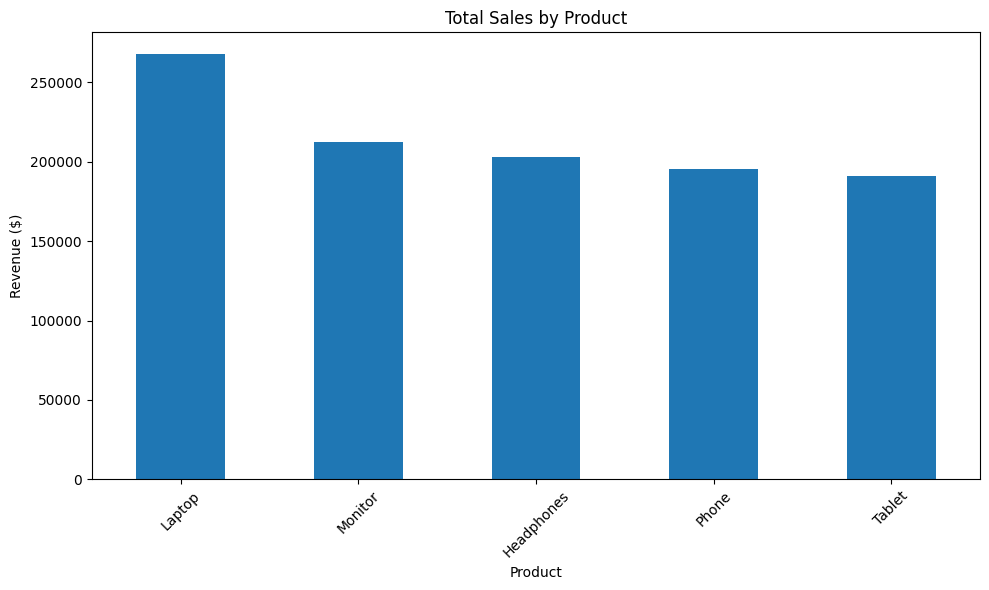

In [742]:
import matplotlib.pyplot as plt

# Calculate sales by product
product_sales = df.groupby("Product")["Total_Sales"].sum().sort_values(ascending=False)

# Create bar chart
product_sales.plot(kind="bar", figsize=(10, 6))

plt.title("Total Sales by Product")
plt.xlabel("Product")
plt.ylabel("Revenue ($)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

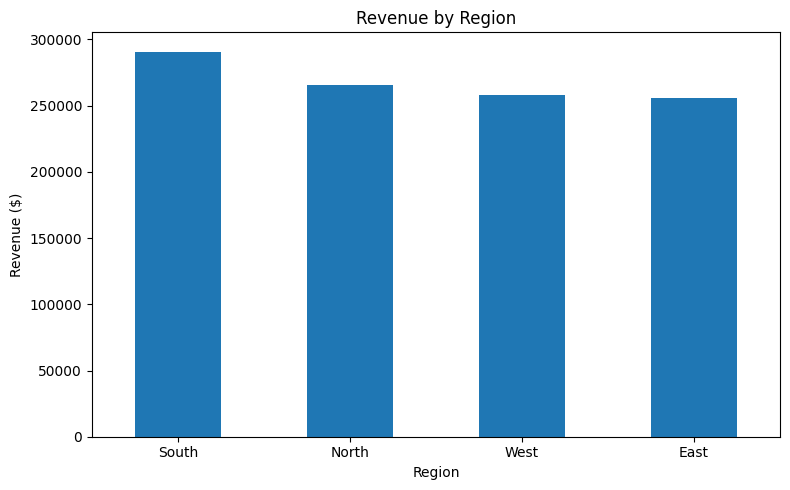

In [743]:
# Calculate revenue by region
region_sales = df.groupby("Region")["Total_Sales"].sum().sort_values(ascending=False)

# Create chart
region_sales.plot(kind="bar", figsize=(8, 5))

plt.title("Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Revenue ($)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

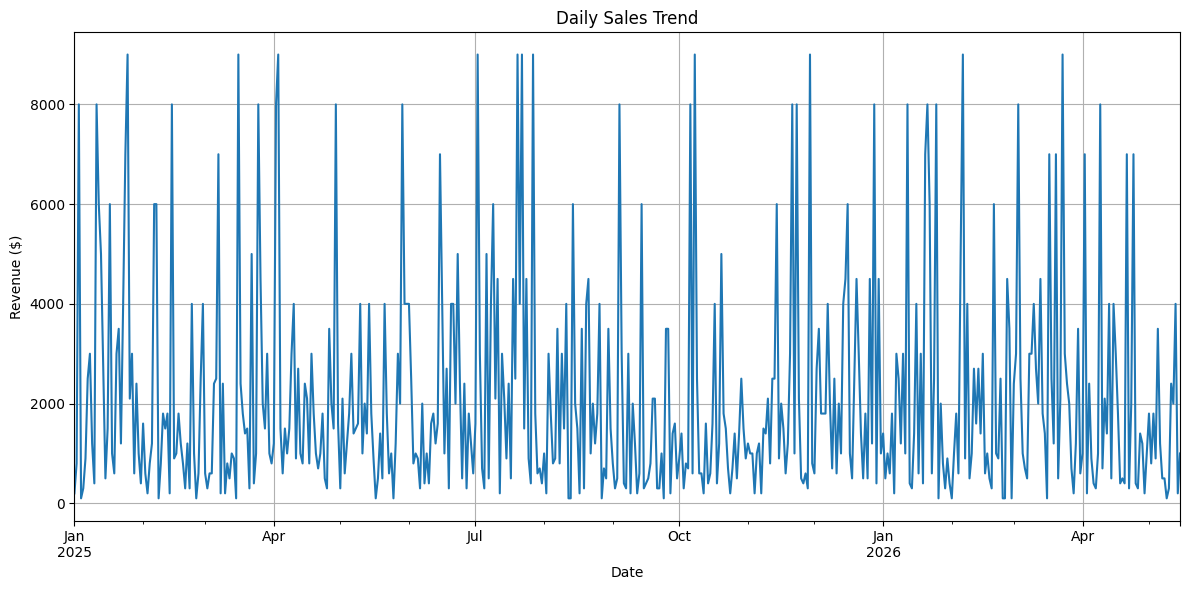

In [744]:
# Calculate sales over time
daily_sales = df.groupby("Date")["Total_Sales"].sum()

# Create line chart
daily_sales.plot(kind="line", figsize=(12, 6))

plt.title("Daily Sales Trend")
plt.xlabel("Date")
plt.ylabel("Revenue ($)")
plt.grid(True)
plt.tight_layout()

plt.show()

In [745]:
# Find the best-performing product
best_product = product_sales.idxmax()
best_revenue = product_sales.max()

print("Best-Selling Product:", best_product)
print(f"Revenue Generated: ${best_revenue:,.2f}")

Best-Selling Product: Laptop
Revenue Generated: $268,100.00


In [746]:
# Analyze the number of units sold per product
units_sold = df.groupby("Product")["Quantity"].sum().sort_values(ascending=False)

print("Units Sold by Product:")
print(units_sold)

Units Sold by Product:
Product
Headphones    531
Laptop        513
Monitor       495
Tablet        471
Phone         469
Name: Quantity, dtype: int64


In [747]:
# Create a business sales summary

total_revenue = df["Total_Sales"].sum()
total_orders = df["Order_ID"].nunique()
total_units = df["Quantity"].sum()
average_order_value = df["Total_Sales"].mean()

print("===== BUSINESS SALES SUMMARY =====")
print(f"Total Revenue: ${total_revenue:,.2f}")
print(f"Total Orders: {total_orders}")
print(f"Units Sold: {total_units:,}")
print(f"Average Order Value: ${average_order_value:,.2f}")
print(f"Best Revenue Product: {product_sales.idxmax()}")
print(f"Top Sales Region: {region_sales.idxmax()}")

===== BUSINESS SALES SUMMARY =====
Total Revenue: $1,070,200.00
Total Orders: 500
Units Sold: 2,479
Average Order Value: $2,140.40
Best Revenue Product: Laptop
Top Sales Region: South


In [748]:
# Monthly sales analysis

df["Month"] = df["Date"].dt.to_period("M")

monthly_sales = df.groupby("Month")["Total_Sales"].sum()

print("Monthly Revenue:")
print(monthly_sales)

Monthly Revenue:
Month
2025-01    85900
2025-02    50300
2025-03    63700
2025-04    68700
2025-05    60800
2025-06    58700
2025-07    94600
2025-08    59000
2025-09    45100
2025-10    53500
2025-11    62500
2025-12    74800
2026-01    70900
2026-02    56400
2026-03    83500
2026-04    60800
2026-05    21000
Freq: M, Name: Total_Sales, dtype: int64


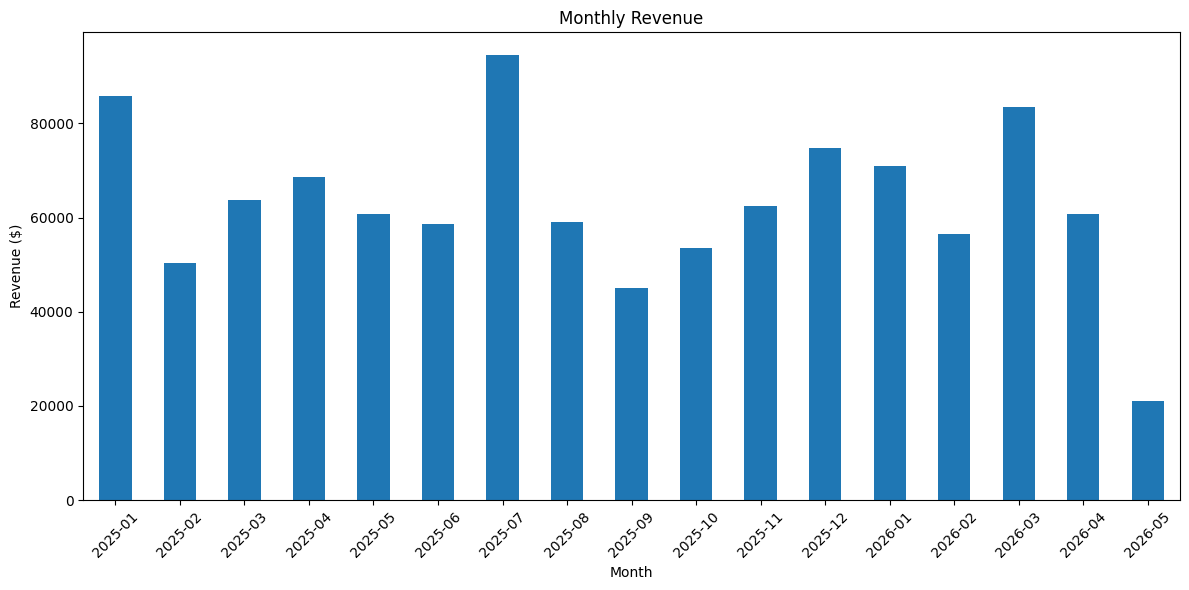

In [749]:
# Visualize monthly revenue

monthly_sales.plot(kind="bar", figsize=(12, 6))

plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue ($)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [750]:
# Average quantity per order by product

average_quantity = df.groupby("Product")["Quantity"].mean().sort_values(ascending=False)

print("Average Quantity per Order by Product:")
print(average_quantity)

Average Quantity per Order by Product:
Product
Monitor       5.322581
Tablet        5.175824
Phone         4.936842
Headphones    4.741071
Laptop        4.706422
Name: Quantity, dtype: float64


In [751]:
# Compare revenue across products

sales_comparison = df.groupby("Product")["Total_Sales"].sum().sort_values(ascending=False)

print("Revenue Comparison:")
print(sales_comparison)

# Calculate each product's percentage of total revenue
sales_percentage = (sales_comparison / sales_comparison.sum()) * 100

print("\nRevenue Percentage:")
print(sales_percentage.round(2))

Revenue Comparison:
Product
Laptop        268100
Monitor       212700
Headphones    203000
Phone         195300
Tablet        191100
Name: Total_Sales, dtype: int64

Revenue Percentage:
Product
Laptop        25.05
Monitor       19.87
Headphones    18.97
Phone         18.25
Tablet        17.86
Name: Total_Sales, dtype: float64


In [752]:
# Find the lowest-revenue product

worst_product = product_sales.idxmin()
worst_revenue = product_sales.min()

print("Lowest Revenue Product:", worst_product)
print(f"Revenue Generated: ${worst_revenue:,.2f}")

Lowest Revenue Product: Tablet
Revenue Generated: $191,100.00


In [753]:
# Analyze sales by product within each region

regional_product_sales = df.groupby(["Region", "Product"])["Total_Sales"].sum()

print(regional_product_sales)

Region  Product   
East    Headphones    47700
        Laptop        65900
        Monitor       40900
        Phone         60100
        Tablet        41100
North   Headphones    34000
        Laptop        67300
        Monitor       65900
        Phone         46900
        Tablet        51600
South   Headphones    66900
        Laptop        68700
        Monitor       65100
        Phone         33500
        Tablet        56600
West    Headphones    54400
        Laptop        66200
        Monitor       40800
        Phone         54800
        Tablet        41800
Name: Total_Sales, dtype: int64


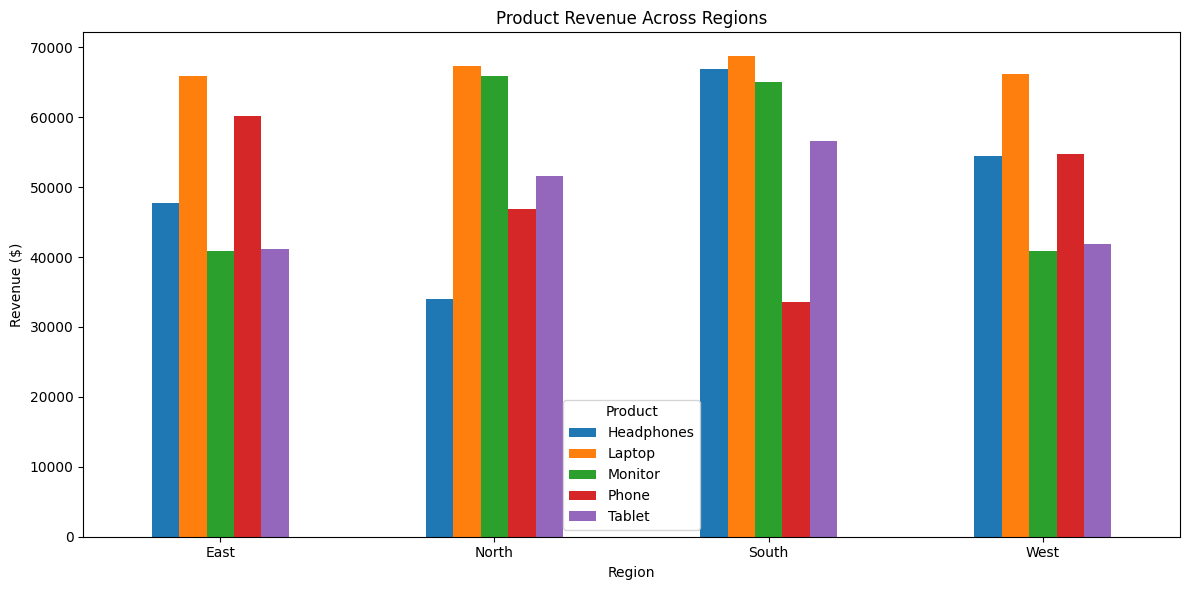

In [754]:
# Create a regional product sales chart

regional_product_pivot = df.pivot_table(
    index="Region",
    columns="Product",
    values="Total_Sales",
    aggfunc="sum"
)

regional_product_pivot.plot(kind="bar", figsize=(12, 6))

plt.title("Product Revenue Across Regions")
plt.xlabel("Region")
plt.ylabel("Revenue ($)")
plt.xticks(rotation=0)
plt.legend(title="Product")
plt.tight_layout()

plt.show()

In [755]:
# Calculate daily sales percentage change

daily_sales = df.groupby("Date")["Total_Sales"].sum()

sales_growth = daily_sales.pct_change() * 100

print("Daily Sales Growth (%):")
print(sales_growth.head(10))

Daily Sales Growth (%):
Date
2025-01-01           NaN
2025-01-02    300.000000
2025-01-03    900.000000
2025-01-04    -98.750000
2025-01-05    200.000000
2025-01-06    200.000000
2025-01-07    177.777778
2025-01-08     20.000000
2025-01-09    -60.000000
2025-01-10    -66.666667
Name: Total_Sales, dtype: float64


In [756]:
# Find the day with the highest revenue

daily_sales = df.groupby("Date")["Total_Sales"].sum()

best_day = daily_sales.idxmax()
best_day_revenue = daily_sales.max()

print("Highest Sales Day:", best_day)
print(f"Revenue: ${best_day_revenue:,.2f}")

Highest Sales Day: 2025-01-25 00:00:00
Revenue: $9,000.00


In [757]:
# Sales performance dashboard

print("========== SALES DASHBOARD ==========")
print(f"Total Revenue: ${df['Total_Sales'].sum():,.2f}")
print(f"Total Orders: {df['Order_ID'].nunique():,}")
print(f"Total Units Sold: {df['Quantity'].sum():,}")
print(f"Average Order Value: ${df['Total_Sales'].mean():,.2f}")
print(f"Top Product: {product_sales.idxmax()}")
print(f"Top Region: {region_sales.idxmax()}")
print(f"Lowest Revenue Product: {product_sales.idxmin()}")
print("====================================")

========== SALES DASHBOARD ==========
Total Revenue: $1,070,200.00
Total Orders: 500
Total Units Sold: 2,479
Average Order Value: $2,140.40
Top Product: Laptop
Top Region: South
Lowest Revenue Product: Tablet


In [758]:
# Save our sales dataset as a CSV file

df.to_csv("sales_data.csv", index=False)

print("Sales dataset saved successfully!")

Sales dataset saved successfully!


In [759]:
import pandas as pd

df = pd.read_csv("sales_data-2.csv")

df.head()

,Order_ID,Date,Product,Region,Quantity,Unit_Price,Total_Sales,Month
0,1001,2025-01-01,Headphones,South,2,100,200,2025-01
1,1002,2025-01-02,Monitor,West,8,100,800,2025-01
2,1003,2025-01-03,Tablet,West,8,1000,8000,2025-01
3,1004,2025-01-04,Monitor,North,1,100,100,2025-01
4,1005,2025-01-05,Monitor,South,3,100,300,2025-01


In [760]:
df.shape

(500, 8)

In [761]:
df.columns

Index(['Order_ID', 'Date', 'Product', 'Region', 'Quantity', 'Unit_Price',
       'Total_Sales', 'Month'],
      dtype='object')

In [762]:
df.isnull().sum()

,0
Order_ID,0
Date,0
Product,0
Region,0
Quantity,0
Unit_Price,0
Total_Sales,0
Month,0


In [763]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Order_ID     500 non-null    int64 
 1   Date         500 non-null    object
 2   Product      500 non-null    object
 3   Region       500 non-null    object
 4   Quantity     500 non-null    int64 
 5   Unit_Price   500 non-null    int64 
 6   Total_Sales  500 non-null    int64 
 7   Month        500 non-null    object
dtypes: int64(4), object(4)
memory usage: 31.4+ KB


In [764]:
df["Total_Sales"].sum()

np.int64(1070200)

In [765]:
df.groupby("Product")["Quantity"].sum().sort_values(ascending=False)

,Quantity
Product,
Headphones,531
Laptop,513
Monitor,495
Tablet,471
Phone,469


In [766]:
df.groupby("Region")["Total_Sales"].sum().sort_values(ascending=False)

,Total_Sales
Region,
South,290800
North,265700
West,258000
East,255700


In [767]:
df.groupby(["Region", "Product"])["Total_Sales"].sum().sort_values(ascending=False)

,,Total_Sales
Region,Product,
South,Laptop,68700
North,Laptop,67300
South,Headphones,66900
West,Laptop,66200
North,Monitor,65900
East,Laptop,65900
South,Monitor,65100
East,Phone,60100
South,Tablet,56600


In [768]:
product_percentage = (df.groupby("Product")["Total_Sales"].sum() / df["Total_Sales"].sum()) * 100

product_percentage.sort_values(ascending=False)

,Total_Sales
Product,
Laptop,25.051392
Monitor,19.874790
Headphones,18.968417
Phone,18.248925
Tablet,17.856475


In [769]:
lowest_product = product_percentage.idxmin()
lowest_percentage = product_percentage.min()

print("Lowest Revenue Product:", lowest_product)
print(f"Revenue Share: {lowest_percentage:.2f}%")

Lowest Revenue Product: Tablet
Revenue Share: 17.86%


In [770]:
print("===== BUSINESS RECOMMENDATIONS =====")

print("1. Invest more in the product generating the highest revenue:", product_sales.idxmax())

print("2. Investigate the product generating the lowest revenue:", product_sales.idxmin())

print("3. Focus marketing efforts on the strongest region:", region_sales.idxmax())

print("4. Analyze sales trends to identify the strongest sales periods.")

print("5. Use sales data to improve inventory planning and avoid stock shortages.")

===== BUSINESS RECOMMENDATIONS =====
1. Invest more in the product generating the highest revenue: Laptop
2. Investigate the product generating the lowest revenue: Tablet
3. Focus marketing efforts on the strongest region: South
4. Analyze sales trends to identify the strongest sales periods.
5. Use sales data to improve inventory planning and avoid stock shortages.


In [771]:
print("===== PROJECT 1: SALES ANALYTICS =====")
print()
print("This project analyzed 500 sales records.")
print(f"Total Revenue: ${df['Total_Sales'].sum():,.2f}")
print(f"Total Orders: {df['Order_ID'].nunique()}")
print(f"Total Units Sold: {df['Quantity'].sum():,}")
print(f"Top Product: {product_sales.idxmax()}")
print(f"Top Region: {region_sales.idxmax()}")
print()
print("Goal: Use data to help businesses make better sales and inventory decisions.")

===== PROJECT 1: SALES ANALYTICS =====

This project analyzed 500 sales records.
Total Revenue: $1,070,200.00
Total Orders: 500
Total Units Sold: 2,479
Top Product: Laptop
Top Region: South

Goal: Use data to help businesses make better sales and inventory decisions.
